In [1]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'scripts/finetune.py').exists(), 'Start Jupyter from the repository root'
CHECKPOINT = 'checkpoints/SuperSloMo.ckpt'
DEVICE = 'cuda'

def train(out, epochs, lr, extra):
    cmd = [sys.executable, 'scripts/finetune.py', '--dataset', 'dataset/train',
           '--num-train', '400', '--num-val', '50', '--num-test', '50',
           '--epochs', str(epochs), '--batch-size', '4', '--crop', '256', '256',
           '--workers', '2', '--device', DEVICE, '--amp', '--cosine',
           '--lr', str(lr), '--out', out, *extra]
    result = subprocess.run(
    cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    )
    print(result.stdout)
    result.check_returncode()
# Reduce crop if your images are smaller, or batch size if GPU memory is limited.

# train('runs/midpoint_scratch',2, 1e-5, ['--scratch', '--split-file', 'runs/midpoint_finetune/split.json'])

In [2]:
train('runs/midpoint_scratch',100, 1e-5, ['--scratch', '--split-file', 'runs/midpoint_finetune/split.json'])

epoch 0 (before fine-tuning): val PSNR 25.227  SSIM 0.7473  (N=50)
d:\Avyay\sem_7\dip_project\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(
epoch 1 step 0/100 loss 0.1601 recon 0.0423 lr 1.00e-05
epoch 1 step 25/100 loss 0.1201 recon 0.0281 lr 1.00e-05
epoch 1 step 50/100 loss 0.1360 recon 0.0338 lr 1.00e-05
epoch 1 step 75/100 loss 0.1330 recon 0.0291 lr 1.00e-05
epoch 1: train loss 0.1391  val PSNR 25.232  SSIM 0.7474  (45s)
  new best -> runs\midpoint_scratch\best.pt
epoch 2 step 0/100 loss 0.1408 recon 0.0334 lr 1.00e-05
epoch 2 step 25/100 loss 0.1957 recon 0.0489 lr 1.0

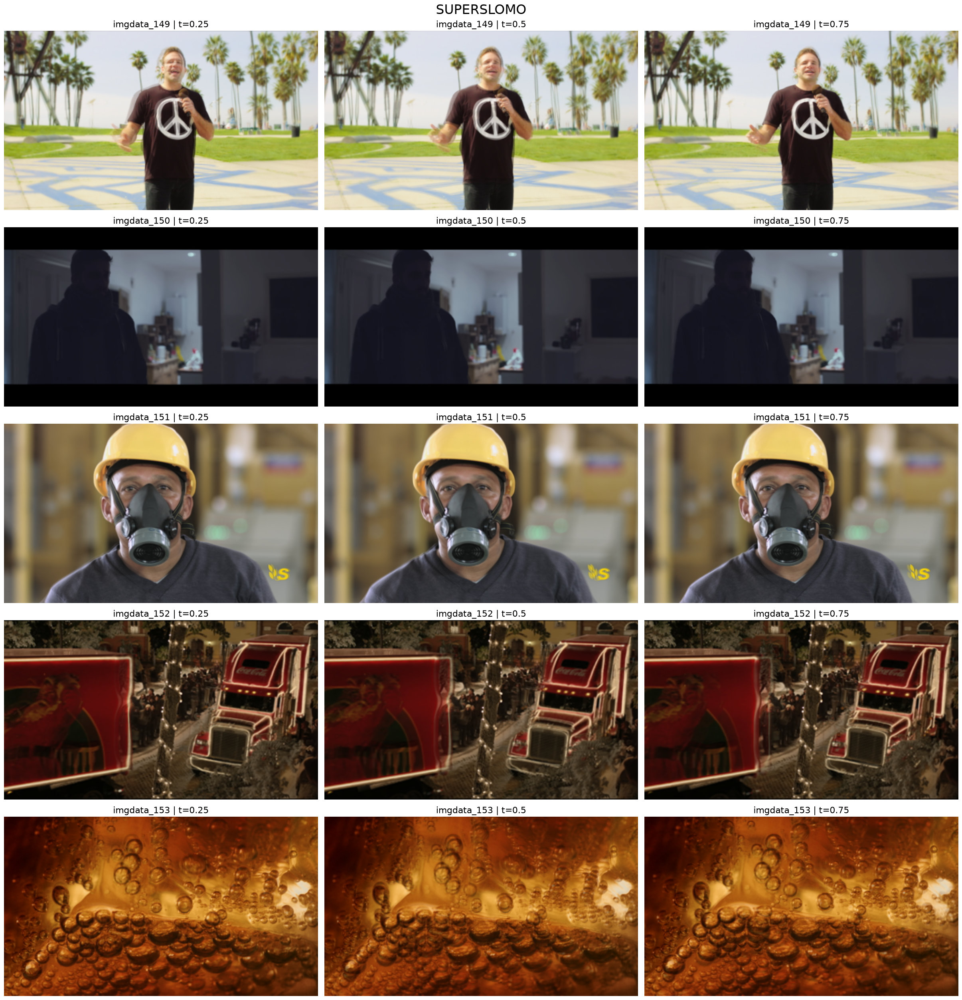

Saved: outputs\method_comparison3_149_153\superslomo_comparison.png


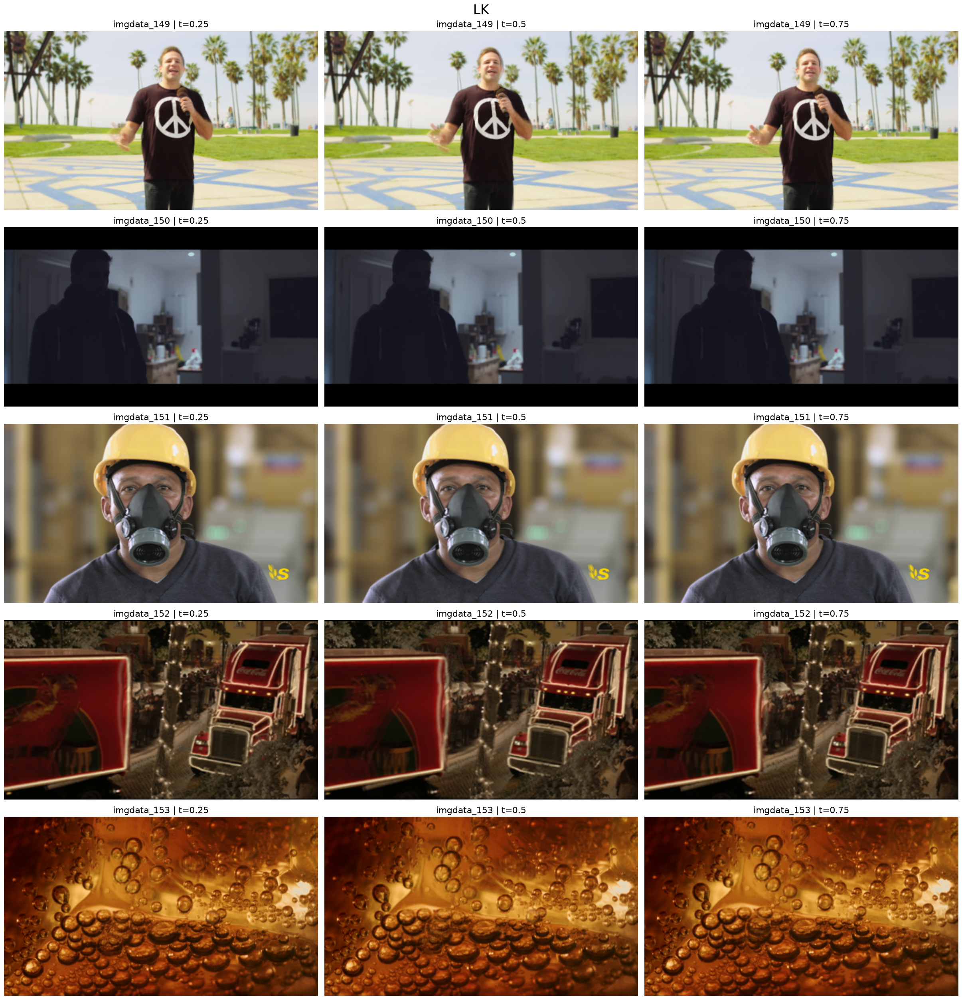

Saved: outputs\method_comparison3_149_153\lk_comparison.png


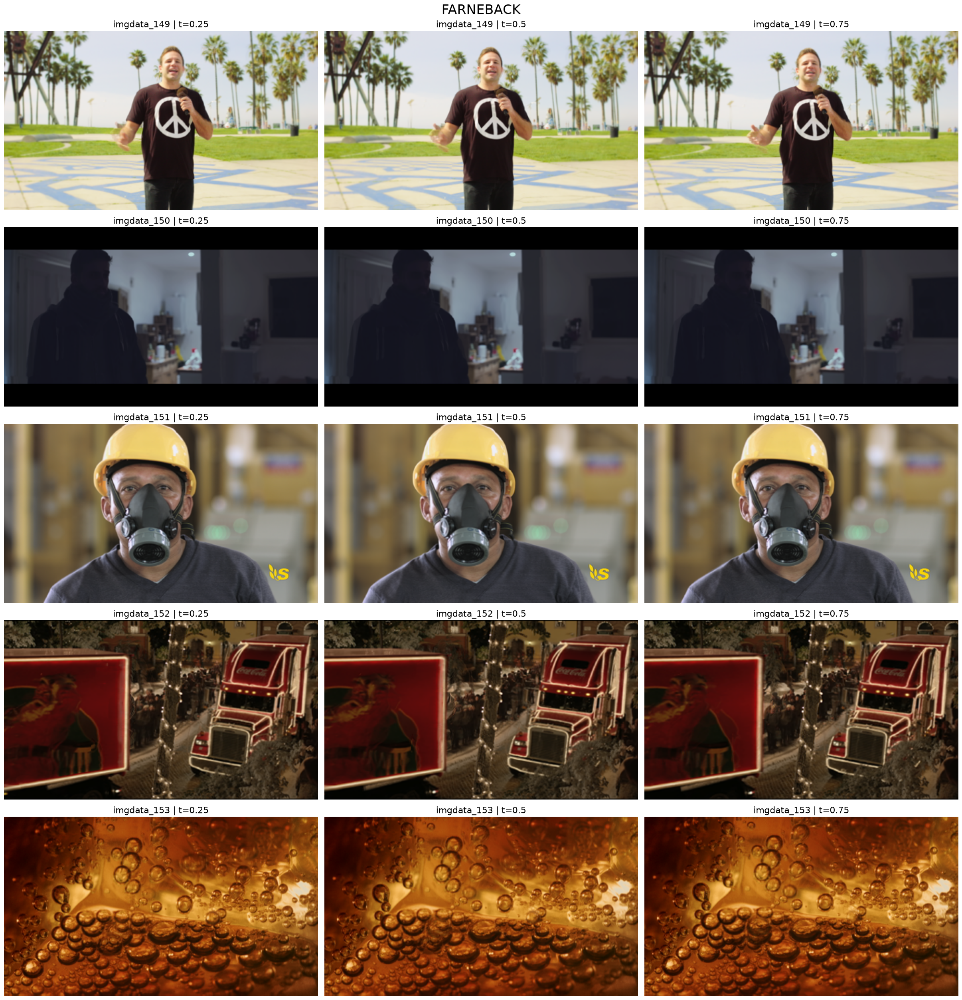

Saved: outputs\method_comparison3_149_153\farneback_comparison.png


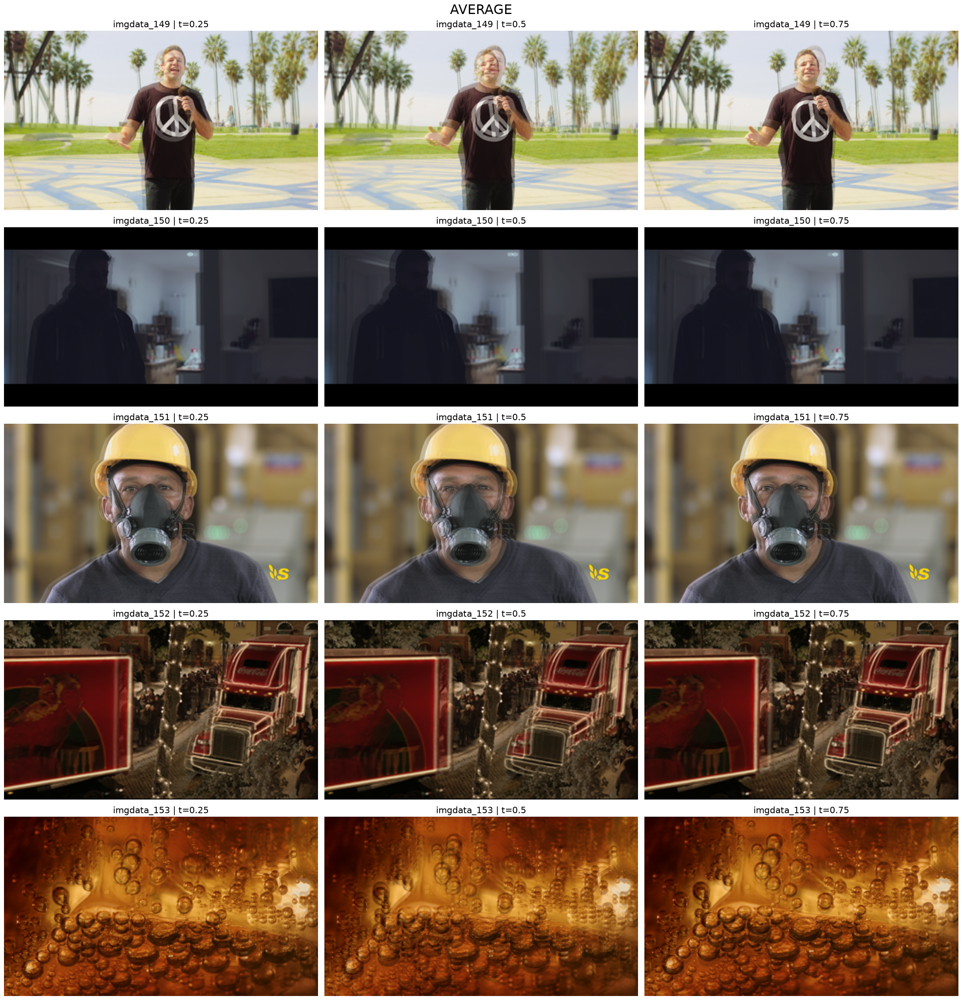

Saved: outputs\method_comparison3_149_153\average_comparison.png


In [3]:
from superslomo.inference import Interpolator
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset = Path("dataset/train")
out = Path("outputs/method_comparison3_149_153")
out.mkdir(parents=True, exist_ok=True)

sample_ids = range(149, 154)
times = [0.25, 0.5, 0.75]

methods = {
    "superslomo": Interpolator.from_checkpoint(
        "superslomo",
        "runs/midpoint_scratch/best.pt",
        device="cuda",
    ),
    "lk": Interpolator("lk"),
    "farneback": Interpolator("farneback"),
    "average": Interpolator("average"),
}


def read_rgb(path):
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Could not read: {path.resolve()}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


# Read endpoints once; im2 is not used for prediction.
pairs = {}
for sample_id in sample_ids:
    folder = dataset / f"imgdata_{sample_id}"
    pairs[sample_id] = (
        read_rgb(folder / "im1.png"),
        read_rgb(folder / "im3.png"),
    )

for method, interpolator in methods.items():
    method_out = out / method
    method_out.mkdir(parents=True, exist_ok=True)

    fig, axes = plt.subplots(
        len(pairs), len(times),
        figsize=(24, 25),
        squeeze=False,
        layout="constrained",
    )

    for row, (sample_id, (img1, img3)) in enumerate(pairs.items()):
        predictions = interpolator(img1, img3, times)

        for col, (t, frame) in enumerate(zip(times, predictions)):
            ax = axes[row, col]
            ax.imshow(frame)
            ax.set_title(f"imgdata_{sample_id} | t={t}", fontsize=16)
            ax.axis("off")

            # OpenCV expects BGR when saving.
            filename = method_out / f"imgdata_{sample_id}_t{t:.2f}.png"
            saved = cv2.imwrite(
                str(filename),
                cv2.cvtColor(frame, cv2.COLOR_RGB2BGR),
            )
            if not saved:
                raise OSError(f"Could not save: {filename}")

    fig.suptitle(method.upper(), fontsize=24)
    figure_path = out / f"{method}_comparison.png"
    fig.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {figure_path}")